In [407]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/house-prices-advanced-regression-techniques


In [408]:
from pathlib import Path
from scipy.stats import boxcox_normmax,skew 
from scipy.special import boxcox1p

import math
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [409]:
# Load data
train = pd.read_csv(Path(path) / "train.csv")
test = pd.read_csv(Path(path) / "test.csv")

print(train.shape, test.shape)

(1460, 81) (1459, 80)


In [410]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [411]:
train_ID = train['Id']
test_ID = test['Id']

train.drop(['Id'], axis=1, inplace=True)
test.drop(['Id'], axis=1, inplace=True)

In [412]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [413]:
numeric_cols = train.select_dtypes(include="number").columns
numeric_cols = numeric_cols.drop(["SalePrice"])
numeric_cols

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold'],
      dtype='object')

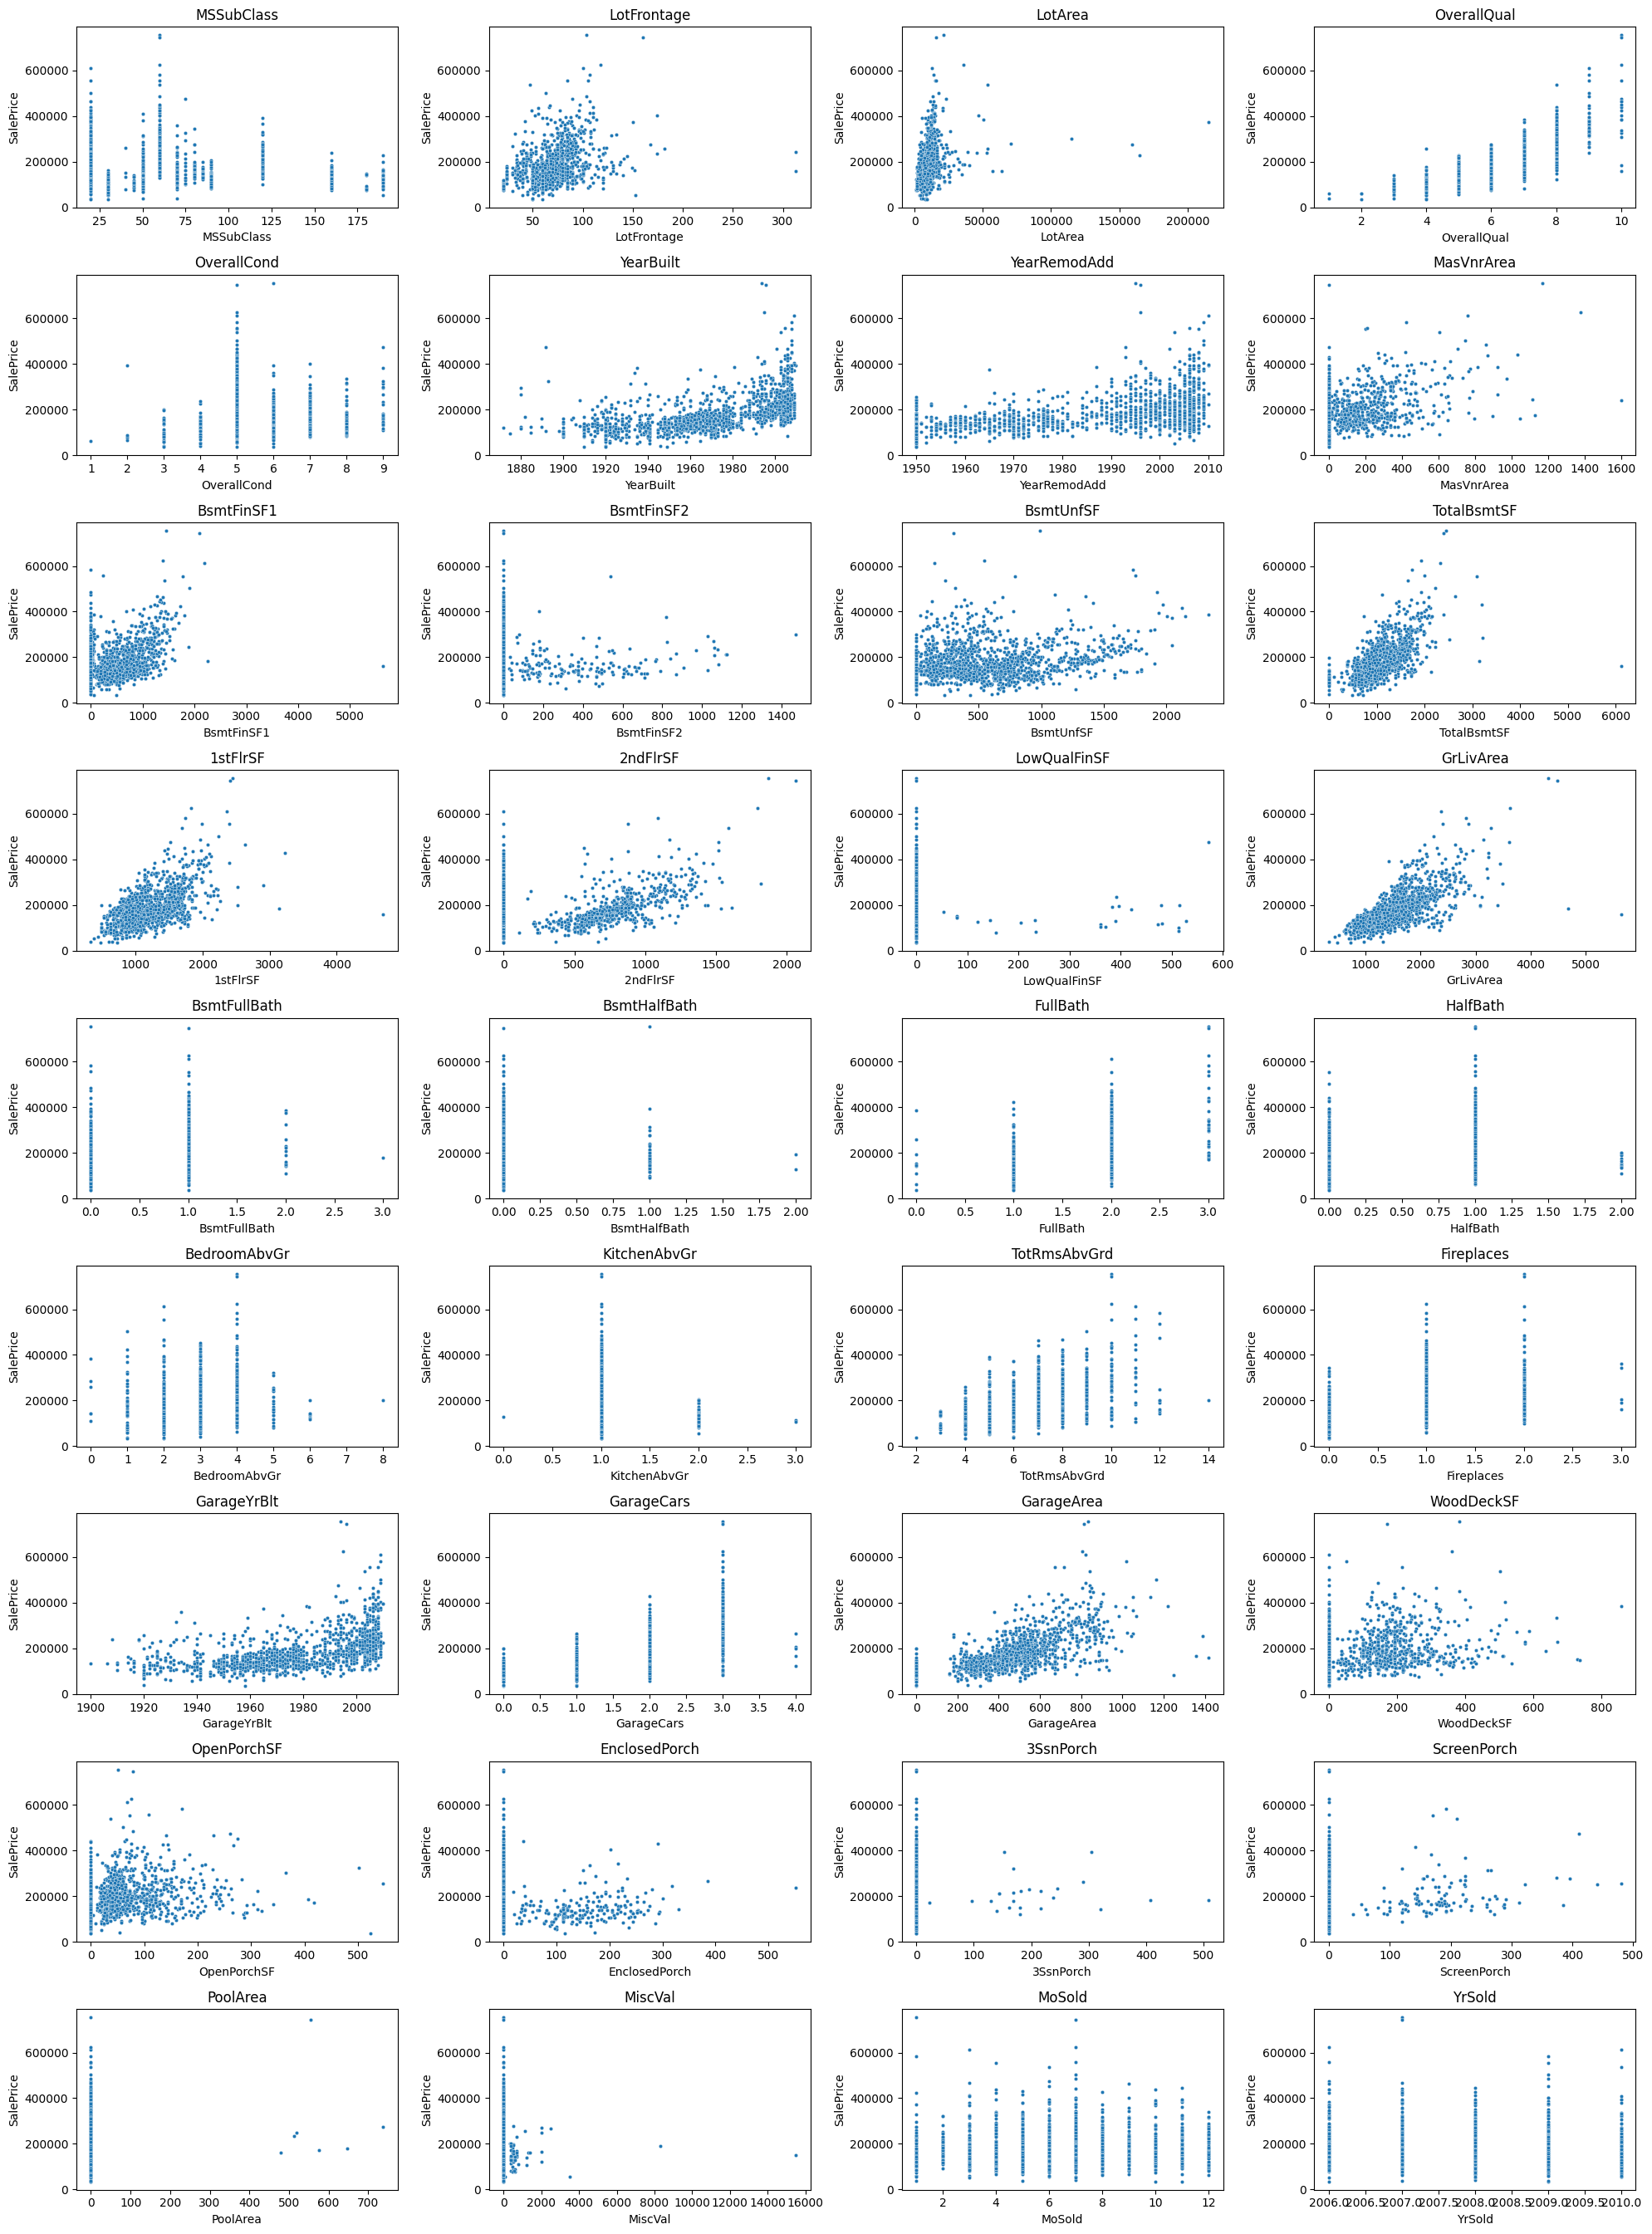

In [414]:
# outliers
ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.scatterplot(
        data=train,
        x=col,
        y="SalePrice",
        ax=axes[i],
        s=10
    )
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [415]:
train[train['GrLivArea'] >= 5000][numeric_cols]

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
1298,60,313.0,63887,10,5,2008,2008,796.0,5644,0,466,6110,4692,950,0,5642,2,0,2,1,3,1,12,3,2008.0,2,1418,214,292,0,0,0,480,0,1,2008


In [416]:
train = train[train.GrLivArea < 5000]
train.reset_index(drop=True, inplace=True)

/tmp/ipykernel_49/434160636.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train['SalePrice'] , fit=stats.norm)


<Axes: xlabel='SalePrice', ylabel='Density'>

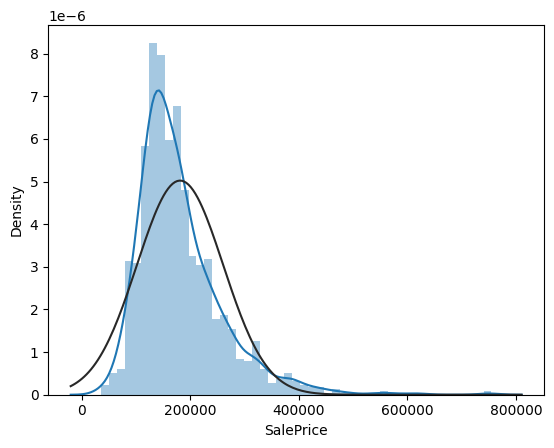

In [417]:
# normality
sns.distplot(train['SalePrice'] , fit=stats.norm)

/tmp/ipykernel_49/2752740045.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train['SalePrice'] , fit=stats.norm)


<Axes: xlabel='SalePrice', ylabel='Density'>

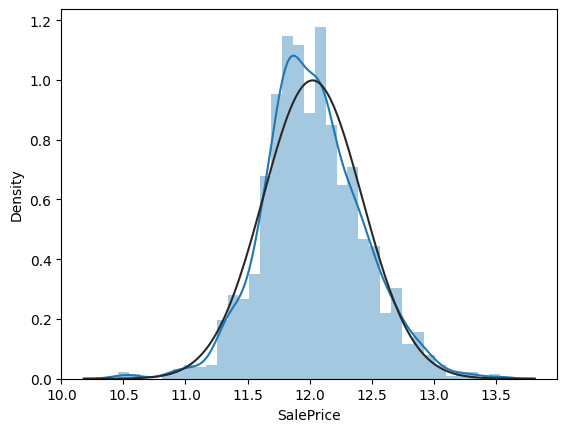

In [418]:
train["SalePrice"] = np.log1p(train["SalePrice"])
sns.distplot(train['SalePrice'] , fit=stats.norm)

<Axes: >

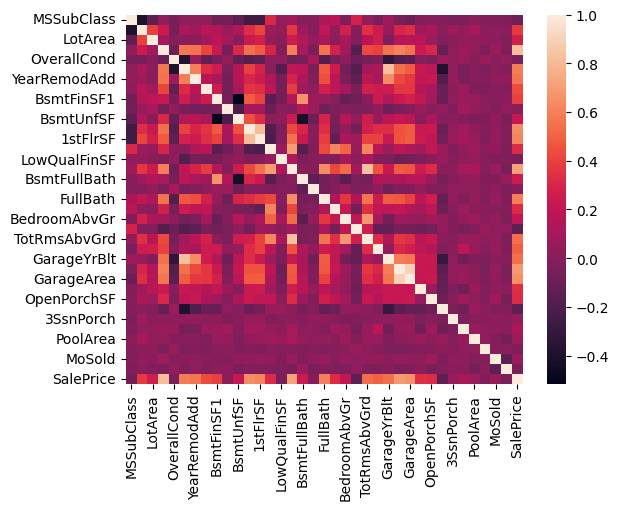

In [419]:
plt.figure(1)
corr = train[numeric_cols.tolist()+['SalePrice']].corr()
sns.heatmap(corr)

In [420]:
# feature engineering
y = train.SalePrice.reset_index(drop=True)
train_features = train.drop(['SalePrice'], axis=1)
test_features = test

features = pd.concat([train_features, test_features]).reset_index(drop=True)

<Axes: >

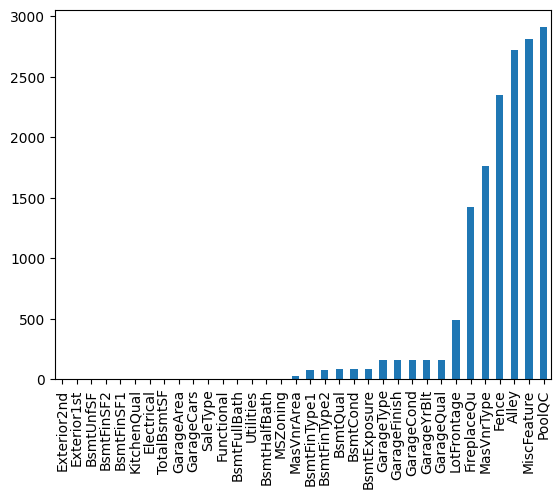

In [421]:
features.isnull().sum().loc[lambda x: x > 0].sort_values().plot.bar()

In [422]:
features["PoolQC"] = features["PoolQC"].fillna("None")
features["MiscFeature"] = features["MiscFeature"].fillna("None")
features["Alley"] = features["Alley"].fillna("None")
features["Fence"] = features["Fence"].fillna("None")
features["MasVnrType"] = features["MasVnrType"].fillna("None")
features["FireplaceQu"] = features["FireplaceQu"].fillna("None")

In [423]:
for col in ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']:
    features[col] = features[col].fillna('None')

In [424]:
for col in ('BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'):
    features[col] = features[col].fillna('None')

In [425]:
features['MSZoning'] = features.groupby('MSSubClass')['MSZoning'].transform(lambda x: x.fillna(x.mode()[0]))

In [426]:
features['Functional'] = features['Functional'].fillna(features['Functional'].mode()[0])
features['Electrical'] = features['Electrical'].fillna(features['Electrical'].mode()[0])
features['KitchenQual'] = features['KitchenQual'].fillna(features['KitchenQual'].mode()[0])
features['Exterior1st'] = features['Exterior1st'].fillna(features['Exterior1st'].mode()[0]) 
features['Exterior2nd'] = features['Exterior2nd'].fillna(features['Exterior2nd'].mode()[0])
features['SaleType'] = features['SaleType'].fillna(features['SaleType'].mode()[0])

In [427]:
features['Utilities'].value_counts(dropna=False)

Utilities
AllPub    2915
NaN          2
NoSeWa       1
Name: count, dtype: int64

In [428]:
features = features.drop(['Utilities'], axis=1)

In [429]:
for col in ('GarageYrBlt', 'GarageArea', 'GarageCars'):
    features[col] = features[col].fillna(0)

In [430]:
features['LotFrontage'] = features.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

In [431]:
for col in ('BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF','TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath'):
    features[col] = features[col].fillna(0)

In [432]:
features["MasVnrArea"] = features["MasVnrArea"].fillna(0)

In [433]:
features.isnull().sum().loc[lambda x: x > 0]

Series([], dtype: int64)

In [434]:
features['OverallCond'].value_counts(dropna=False)

OverallCond
5    1644
6     531
7     390
8     144
4     101
3      50
9      41
2      10
1       7
Name: count, dtype: int64

In [435]:
features['MSSubClass'] = features['MSSubClass'].apply(str)

In [436]:
# feature engineering
features['TotalSF'] = features['TotalBsmtSF'] + features['1stFlrSF'] + features['2ndFlrSF']
features['TotalBath'] = (features['FullBath'] + (0.5 * features['HalfBath']) + features['BsmtFullBath'] + (0.5 * features['BsmtHalfBath']))
features['TotalPorchSF'] = features['OpenPorchSF'] + features['EnclosedPorch'] + features['3SsnPorch'] + features['ScreenPorch'] + features['WoodDeckSF']

features['HouseAge'] = features['YrSold'] - features['YearBuilt']
features['RemodAge'] = features['YrSold'] - features['YearRemodAdd']
features['GarageAge'] = np.where(
    features['GarageYrBlt'] > 0,
    features['YrSold'] - features['GarageYrBlt'],
    0
)

features['HasGarage'] = (features['GarageArea'] > 0).astype(int)
features['HasBasement'] = (features['TotalBsmtSF'] > 0).astype(int)
features['HasPool'] = (features['PoolArea'] > 0).astype(int)
features['Has2ndFloor'] = (features['2ndFlrSF'] > 0).astype(int)
features['HasFirePlace'] = (features['Fireplaces'] > 0).astype(int)

In [437]:
numeric_dtypes = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
numerics = []
for i in features.columns:
    if features[i].dtype in numeric_dtypes:
        numerics.append(i)

skew_features = features[numerics].apply(lambda x: skew(x)).sort_values(ascending=False)
skew_features

MiscVal          21.943434
PoolArea         17.691725
HasPool          15.497445
LotArea          13.028401
LowQualFinSF     12.086650
3SsnPorch        11.374072
KitchenAbvGr      4.301402
BsmtFinSF2        4.145323
EnclosedPorch     4.003118
ScreenPorch       3.945898
BsmtHalfBath      3.930795
MasVnrArea        2.617316
OpenPorchSF       2.539224
WoodDeckSF        1.843657
TotalPorchSF      1.378554
1stFlrSF          1.281308
GrLivArea         1.128176
LotFrontage       1.103367
TotalSF           1.082291
BsmtFinSF1        0.991631
BsmtUnfSF         0.918986
2ndFlrSF          0.862902
TotRmsAbvGrd      0.751537
Fireplaces        0.724696
TotalBsmtSF       0.697798
HalfBath          0.695616
BsmtFullBath      0.621464
HouseAge          0.598312
OverallCond       0.569813
TotalBath         0.489364
GarageAge         0.453525
RemodAge          0.449775
BedroomAbvGr      0.326446
Has2ndFloor       0.289483
GarageArea        0.216927
MoSold            0.196678
OverallQual       0.193372
F

In [438]:
high_skew = skew_features[skew_features > 1]
skew_index = high_skew.index

for i in skew_index:
    features[i] = boxcox1p(features[i], boxcox_normmax(features[i]+1, method='mle'))

In [439]:
# cat_cols = features.select_dtypes(
#     include=['object', 'string']
# ).columns

# features[cat_cols] = features[cat_cols].astype('category')

features = pd.get_dummies(features).reset_index(drop=True)
features.shape

(2918, 325)

In [440]:
X_train = features.iloc[:len(y), :]
X_test = features.iloc[len(y):, :]
X_train.shape, y.shape, X_test.shape

((1459, 325), (1459,), (1459, 325))

In [441]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [442]:
kfolds = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_rmse(model):
    return -cross_val_score(
        model,
        X_train,
        y,
        scoring='neg_root_mean_squared_error',
        cv=kfolds
    )

In [443]:
alphas_alt = np.logspace(-2, 2, 40)
ridge = make_pipeline(RobustScaler(), RidgeCV(alphas=alphas_alt, cv=kfolds))

In [444]:
lightgbm = LGBMRegressor(
    objective='regression', 
    num_leaves=4,
    learning_rate=0.01, 
    n_estimators=5000,
    max_bin=200, 
    bagging_fraction=0.75,
    bagging_freq=5, 
    bagging_seed=7,
    feature_fraction=0.2,
    feature_fraction_seed=7,
    verbose=-1,
)

In [445]:
xgboost = XGBRegressor(
    learning_rate=0.01, 
    n_estimators=3460,
    max_depth=3, 
    min_child_weight=0,
    gamma=0, 
    subsample=0.7,
    colsample_bytree=0.7,
    objective='reg:squarederror', 
    nthread=-1,
    scale_pos_weight=1, 
    seed=27,
    reg_alpha=0.00006
)

In [446]:
score = cv_rmse(ridge)
print("\nRidge score: {:.4f} ({:.4f})\n".format(score.mean(), score.std()))


Ridge score: 0.1186 (0.0121)



In [447]:
score = cv_rmse(lightgbm)
print("LGBM score: {:.4f} ({:.4f})\n" .format(score.mean(), score.std()))

LGBM score: 0.1219 (0.0104)



In [448]:
score = cv_rmse(xgboost)
print("Xgboost score: {:.4f} ({:.4f})\n".format(score.mean(), score.std()))

Xgboost score: 0.1211 (0.0109)



In [449]:
ridge_model = ridge.fit(X_train, y)
xgb_model = xgboost.fit(X_train, y)
lgb_model = lightgbm.fit(X_train, y)

In [453]:
def blend_models_predict(X):
    return  (0.4 * ridge.predict(X)) + (0.3 * xgb_model.predict(X)) + (0.3 * lgb_model.predict(X)) 

def rmsle(y, y_pred):
    return np.sqrt(mean_squared_error(y, y_pred))
            
print('RMSLE score on train data:')
print(rmsle(y, blend_models_predict(X_train)))

RMSLE score on train data:
0.07472106640348834


In [454]:
res = pd.DataFrame()
res['Id'] = test_ID
res['SalePrice'] = np.expm1(blend_models_predict(X_test))
res.to_csv('submission_10.csv',index=False)